# Imputación de faltantes y valores atípicos de P (periodo detectado automáticamente en el archivo)

Este notebook realiza la imputación de **valores faltantes** y **valores atípicos** de la variable **P** con un enfoque de **Random Forest para series de tiempo**.

## Objetivo metodológico
1. Reconstruir la serie diaria completa por estación.  
2. Identificar días faltantes explícitos.  
3. Detectar valores atípicos mediante criterios robustos de serie temporal.  
4. Convertir los valores atípicos en valores a imputar, conservando trazabilidad.  
5. Crear variables temporales, rezagos y medias móviles.  
6. Entrenar Random Forest con valores válidos observados.  
7. Imputar faltantes y atípicos de forma recursiva.  
8. Exportar dataset detallado, dataset final y tabla de valores imputados.

## Criterio aplicado
Los valores atípicos no se eliminan sin control. Se marcan mediante banderas de auditoría y luego se imputan con el mismo procedimiento usado para los faltantes.

**Actualización:** se agregó medición del tiempo total de ejecución del notebook y exportación del archivo CSV correspondiente.

**Actualización:** se agregó gráfica comparativa antes/después de la imputación, con marcadores para faltantes y atípicos corregidos.

**Actualización:** las gráficas antes/después ahora se generan automáticamente para todas las estaciones disponibles, sin escribir manualmente el nombre de la estación.

**Corrección técnica:** se agregó la importación `from IPython.display import display, Markdown` para evitar el error `NameError: name 'Markdown' is not defined`.

**Corrección adicional:** se incorporó una regla física para detectar como atípicos los valores `0` en variables donde el cero no es coherente con la serie diaria, como `P`, `PM10` y `PM2.5`. Esta regla permite corregir ceros aislados al inicio o al final de la serie.

**Aclaración de periodo:** el notebook no está configurado para imputar dos años de forma fija. El periodo de imputación se toma automáticamente desde la fecha mínima hasta la fecha máxima del archivo cargado. Si el archivo contiene solo 2022, se imputa únicamente ese año.

In [59]:
# ============================================================
# INICIO DE MEDICIÓN DEL TIEMPO TOTAL DEL NOTEBOOK
# ============================================================

import time
from datetime import datetime

TIEMPO_INICIO_NOTEBOOK = time.perf_counter()
FECHA_HORA_INICIO_NOTEBOOK = datetime.now()

print("Inicio de ejecución del notebook:")
print(FECHA_HORA_INICIO_NOTEBOOK.strftime("%Y-%m-%d %H:%M:%S"))

Inicio de ejecución del notebook:
2026-07-30 22:57:43


In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", None)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 1. Cargar archivo

In [61]:
# ==========================================
# 1. CARGAR ARCHIVO Y CONFIGURACIÓN GENERAL
# ==========================================

VARIABLE = "P"
ruta = f"{VARIABLE}.csv"   # Ajusta esta ruta si el archivo está en otra carpeta
ARCHIVO_BASE = VARIABLE

# Parámetros para detección de atípicos
VENTANA_ROLLING_ATIPICOS = 15
UMBRAL_Z_ROBUSTO = 3.5
MULTIPLICADOR_IQR = 1.5

# Criterio conservador recomendado:
# "MAD_E_IQR": marca atípico si cumple MAD robusto e IQR.
# "MAD_O_IQR": criterio más agresivo.
CRITERIO_COMBINACION_ATIPICOS = "MAD_E_IQR"

# En variables como P y contaminantes, un valor 0 suele representar falla,
# ausencia de registro o dato no confiable cuando la serie diaria tiene valores positivos.
# Para variables donde el cero sí es válido, como precipitación, no se marca como atípico.
VARIABLES_CERO_INVALIDO = ["P", "PM10", "PM25", "PM2.5", "HAire2", "HAire10"]
MARCAR_CERO_COMO_ATIPICO = VARIABLE in VARIABLES_CERO_INVALIDO
UMBRAL_MINIMO_VALIDO = 0

df = pd.read_csv(ruta)
df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")
df[VARIABLE] = pd.to_numeric(df[VARIABLE], errors="coerce")
df = df.sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

print("Dimensión:", df.shape)
print("Variable objetivo:", VARIABLE)
print("Rango temporal:", df["Fecha inicial"].min(), "a", df["Fecha inicial"].max())
display(df.head())

Dimensión: (355, 4)
Variable objetivo: P
Rango temporal: 2022-01-01 00:00:00 a 2022-12-31 00:00:00


,Estacion,Fecha inicial,Fecha final,P
0,PALMIRA,2022-01-01,NaN,674.733333
1,PALMIRA,2022-01-02,NaN,675.304167
2,PALMIRA,2022-01-03,NaN,675.820833
3,PALMIRA,2022-01-04,NaN,674.791667
4,PALMIRA,2022-01-05,NaN,673.908333


In [62]:
# ============================================================
# PERIODO DE IMPUTACIÓN DETECTADO AUTOMÁTICAMENTE
# ============================================================

# El notebook no fuerza dos años. Imputa únicamente el rango de fechas
# contenido en el archivo cargado.
PERIODO_INICIO = df["Fecha inicial"].min()
PERIODO_FIN = df["Fecha inicial"].max()
DIAS_PERIODO = pd.date_range(PERIODO_INICIO, PERIODO_FIN, freq="D").size

print("Periodo detectado en el archivo:")
print("Inicio:", PERIODO_INICIO.date())
print("Fin:", PERIODO_FIN.date())
print("Días esperados:", DIAS_PERIODO)

if DIAS_PERIODO <= 366:
    print("Interpretación: el archivo corresponde aproximadamente a un año de datos.")
else:
    print("Interpretación: el archivo contiene más de un año de datos.")

Periodo detectado en el archivo:
Inicio: 2022-01-01
Fin: 2022-12-31
Días esperados: 365
Interpretación: el archivo corresponde aproximadamente a un año de datos.


## 2. Reconstruir serie diaria completa

Aquí construimos una malla diaria completa entre la fecha mínima y máxima del archivo para cada estación.
Así podemos detectar explícitamente los días faltantes.


In [63]:
# ==========================================
# 2. RECONSTRUIR SERIE DIARIA Y DETECTAR ATÍPICOS
# ==========================================

def detectar_atipicos_robustos_por_estacion(df_in, variable):
    '''
    Detecta valores atípicos por estación usando:
    1. Valores físicamente inválidos: negativos.
    2. Regla IQR global por estación.
    3. Z-score robusto con mediana móvil y MAD móvil.

    El criterio por defecto es conservador: MAD_E_IQR.
    '''
    banderas = pd.Series(False, index=df_in.index)

    for estacion, sub in df_in.groupby("Estacion"):
        sub = sub.sort_values("Fecha inicial")
        idx = sub.index
        s = pd.to_numeric(sub[variable], errors="coerce")

        # Regla física básica.
        # Si MARCAR_CERO_COMO_ATIPICO=True, valores <= 0 se consideran no confiables.
        # Esto corrige casos como ceros aislados al final de la serie de P.
        if MARCAR_CERO_COMO_ATIPICO:
            atipico_fisico = s <= UMBRAL_MINIMO_VALIDO
        else:
            atipico_fisico = s < UMBRAL_MINIMO_VALIDO

        # IQR global por estación
        s_valid = s.dropna()
        if len(s_valid) >= 8:
            q1 = s_valid.quantile(0.25)
            q3 = s_valid.quantile(0.75)
            iqr = q3 - q1
            lim_inf = q1 - MULTIPLICADOR_IQR * iqr
            lim_sup = q3 + MULTIPLICADOR_IQR * iqr
            atipico_iqr = (s < lim_inf) | (s > lim_sup)
        else:
            atipico_iqr = pd.Series(False, index=s.index)

        # MAD móvil centrado
        med_roll = s.rolling(
            window=VENTANA_ROLLING_ATIPICOS,
            center=True,
            min_periods=max(5, VENTANA_ROLLING_ATIPICOS // 3)
        ).median()

        desv_abs = (s - med_roll).abs()

        mad_roll = desv_abs.rolling(
            window=VENTANA_ROLLING_ATIPICOS,
            center=True,
            min_periods=max(5, VENTANA_ROLLING_ATIPICOS // 3)
        ).median()

        mad_roll = mad_roll.replace(0, np.nan)
        z_robusto = 0.6745 * desv_abs / mad_roll
        atipico_mad = z_robusto > UMBRAL_Z_ROBUSTO

        if CRITERIO_COMBINACION_ATIPICOS == "MAD_O_IQR":
            atipico_estacion = atipico_fisico | atipico_iqr | atipico_mad
        else:
            atipico_estacion = atipico_fisico | (atipico_iqr & atipico_mad)

        atipico_estacion = atipico_estacion.fillna(False)
        banderas.loc[idx] = atipico_estacion.values

    return banderas.fillna(False)


rango_fechas = pd.date_range(df["Fecha inicial"].min(), df["Fecha inicial"].max(), freq="D")
estaciones = sorted(df["Estacion"].dropna().unique())

base_completa = (
    pd.MultiIndex.from_product([estaciones, rango_fechas], names=["Estacion", "Fecha inicial"])
    .to_frame(index=False)
)

base = base_completa.merge(
    df[["Estacion", "Fecha inicial", VARIABLE]],
    on=["Estacion", "Fecha inicial"],
    how="left"
)

# Guardar el valor crudo/original antes de limpiar atípicos.
base[f"{VARIABLE}_original"] = base[VARIABLE]

# Faltantes originales detectados por reconstrucción diaria.
base["Fue_faltante_original"] = base[VARIABLE].isna()

# Detección de atípicos sobre la serie observada.
base["Fue_atipico"] = detectar_atipicos_robustos_por_estacion(base, VARIABLE)

# Un valor requiere imputación si estaba faltante o si fue marcado como atípico.
base["Requiere_imputacion"] = base["Fue_faltante_original"] | base["Fue_atipico"]

# Para entrenar e imputar, los atípicos se convierten temporalmente en NaN.
base.loc[base["Fue_atipico"], VARIABLE] = np.nan

# Columna de compatibilidad con las funciones existentes.
base["Fue_faltante"] = base["Requiere_imputacion"]

faltantes_resumen = (
    base.groupby("Estacion")
    .agg(
        registros_validos_para_entrenar=(VARIABLE, "count"),
        faltantes_originales=("Fue_faltante_original", "sum"),
        atipicos_detectados=("Fue_atipico", "sum"),
        total_a_imputar=("Requiere_imputacion", "sum")
    )
    .reset_index()
)

faltantes_resumen["porcentaje_total_a_imputar"] = (
    faltantes_resumen["total_a_imputar"] / len(rango_fechas) * 100
)

display(faltantes_resumen)

dias_a_imputar = base.loc[
    base["Requiere_imputacion"],
    ["Estacion", "Fecha inicial", f"{VARIABLE}_original", "Fue_faltante_original", "Fue_atipico"]
].copy()

display(dias_a_imputar)

faltantes_resumen.to_csv(f"{ARCHIVO_BASE}_resumen_faltantes_atipicos.csv", index=False, encoding="utf-8-sig")
dias_a_imputar.to_csv(f"{ARCHIVO_BASE}_fechas_faltantes_y_atipicos.csv", index=False, encoding="utf-8-sig")

,Estacion,registros_validos_para_entrenar,faltantes_originales,atipicos_detectados,total_a_imputar,porcentaje_total_a_imputar
0,PALMIRA,352,10,3,13,3.561644


,Estacion,Fecha inicial,P_original,Fue_faltante_original,Fue_atipico
74,PALMIRA,2022-03-16,NaN,True,False
85,PALMIRA,2022-03-27,NaN,True,False
86,PALMIRA,2022-03-28,NaN,True,False
87,PALMIRA,2022-03-29,NaN,True,False
88,PALMIRA,2022-03-30,NaN,True,False
89,PALMIRA,2022-03-31,NaN,True,False
90,PALMIRA,2022-04-01,NaN,True,False
91,PALMIRA,2022-04-02,NaN,True,False
92,PALMIRA,2022-04-03,NaN,True,False
99,PALMIRA,2022-04-10,NaN,True,False


## 3. Funciones para crear variables predictoras

Se crean:

- variables de calendario  
- variables cíclicas seno/coseno  
- rezagos de la misma serie  
- medias móviles históricas  
- valor de la otra estación el mismo día


In [64]:
def crear_features(df_long):
    x = df_long.copy().sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

    # Valor de la otra estación el mismo día
    piv = x.pivot(index="Fecha inicial", columns="Estacion", values="P")
    for estacion in x["Estacion"].unique():
        otras = [c for c in piv.columns if c != estacion]
        if len(otras) == 1:
            serie_otras = piv[otras[0]]
        else:
            serie_otras = piv[otras].mean(axis=1)

        mask = x["Estacion"] == estacion
        x.loc[mask, "otra_estacion_mismo_dia"] = x.loc[mask, "Fecha inicial"].map(serie_otras)

    # Variables de calendario
    x["year"] = x["Fecha inicial"].dt.year
    x["month"] = x["Fecha inicial"].dt.month
    x["day"] = x["Fecha inicial"].dt.day
    x["dow"] = x["Fecha inicial"].dt.dayofweek
    x["weekofyear"] = x["Fecha inicial"].dt.isocalendar().week.astype(int)
    x["dayofyear"] = x["Fecha inicial"].dt.dayofyear

    # Codificación cíclica
    x["sin_doy"] = np.sin(2 * np.pi * x["dayofyear"] / 365.25)
    x["cos_doy"] = np.cos(2 * np.pi * x["dayofyear"] / 365.25)
    x["sin_dow"] = np.sin(2 * np.pi * x["dow"] / 7)
    x["cos_dow"] = np.cos(2 * np.pi * x["dow"] / 7)

    # Rezagos
    for lag in [1, 2, 3, 7, 14]:
        x[f"lag_{lag}"] = x.groupby("Estacion")["P"].shift(lag)

    # Estadísticos móviles históricos
    for ventana in [3, 7, 14]:
        x[f"roll_mean_{ventana}"] = (
            x.groupby("Estacion")["P"]
            .transform(lambda s: s.shift(1).rolling(ventana, min_periods=1).mean())
        )
        x[f"roll_std_{ventana}"] = (
            x.groupby("Estacion")["P"]
            .transform(lambda s: s.shift(1).rolling(ventana, min_periods=2).std())
        )

    return x


feature_cols = [
    "otra_estacion_mismo_dia", "year", "month", "day", "dow", "weekofyear", "dayofyear",
    "sin_doy", "cos_doy", "sin_dow", "cos_dow",
    "lag_1", "lag_2", "lag_3", "lag_7", "lag_14",
    "roll_mean_3", "roll_std_3", "roll_mean_7", "roll_std_7", "roll_mean_14", "roll_std_14"
]


## 4. Entrenamiento del modelo de imputación

In [65]:
def entrenar_modelo(df_long):
    feat = crear_features(df_long)
    obs = feat[feat["P"].notna()].copy()

    X = obs[feature_cols].copy()
    X = pd.concat([X, pd.get_dummies(obs["Estacion"], prefix="est")], axis=1)

    # Convertir a numérico y completar vacíos de predictores
    X = X.apply(pd.to_numeric, errors="coerce")
    medianas = X.median(numeric_only=True)
    X = X.fillna(medianas).infer_objects(copy=False)

    y = obs["P"].astype(float).values

    modelo = RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    )
    modelo.fit(X, y)

    columnas_modelo = X.columns.tolist()
    return modelo, medianas, columnas_modelo


## 5. Imputación recursiva

Esto es importante porque algunos faltantes están en bloques consecutivos.
Por eso, a medida que el modelo predice un día faltante, ese valor predicho puede servir como rezago para el siguiente día.


In [66]:
def imputar_rf_recursivo(df_long):
    actual = df_long.copy().sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

    modelo, medianas, columnas_modelo = entrenar_modelo(actual)

    for _ in range(10):
        feat = crear_features(actual)
        faltantes = feat[feat["P"].isna()].sort_values(["Estacion", "Fecha inicial"])

        if faltantes.empty:
            break

        for idx, fila in faltantes.iterrows():
            X_fila = fila[feature_cols].to_frame().T
            dummies = pd.get_dummies(pd.Series([fila["Estacion"]]), prefix="est")
            X_fila = pd.concat([X_fila.reset_index(drop=True), dummies.reset_index(drop=True)], axis=1)

            for col in columnas_modelo:
                if col not in X_fila.columns:
                    X_fila[col] = 0

            X_fila = X_fila[columnas_modelo]
            X_fila = X_fila.apply(pd.to_numeric, errors="coerce")
            X_fila = X_fila.fillna(medianas).infer_objects(copy=False)

            pred = float(modelo.predict(X_fila)[0])
            actual.at[idx, "P"] = pred

    return actual


## 6. Validación con bloques artificialmente ocultos

Antes de imputar los faltantes reales, probamos el método ocultando bloques de días conocidos en **KENNEDY**.
Eso permite medir qué tan bien reconstruye la serie.


In [67]:
def validar_por_bloques(base_original):

    # Seleccionar automáticamente fechas válidas del dataset
    fechas_disponibles = (
        base_original["Fecha inicial"]
        .dropna()
        .sort_values()
        .unique()
    )

    # Crear bloques automáticos
    bloques = []

    for i in range(10, min(40, len(fechas_disponibles)-5), 10):
        bloques.append((fechas_disponibles[i], 3))

    resultados = []
    comparaciones = []

    for fecha_inicio, longitud in bloques:

        fecha_inicio = pd.Timestamp(fecha_inicio)

        fechas_bloque = pd.date_range(
            fecha_inicio,
            periods=longitud,
            freq="D"
        )

        temp = base_original.copy()

        mask = (
            (temp["Estacion"] == "KENNEDY") &
            (temp["Fecha inicial"].isin(fechas_bloque))
        )

        reales = temp.loc[
            mask,
            ["Fecha inicial", "P"]
        ].sort_values("Fecha inicial").copy()

        # Saltar si hay NaN reales
        if reales["P"].isna().any():
            continue

        # Saltar si no existe el bloque completo
        if len(reales) != longitud:
            continue

        # Crear faltantes artificiales
        temp.loc[mask, "P"] = np.nan

        # Imputar
        imputado = imputar_rf_recursivo(temp)

        pred = imputado.loc[
            (imputado["Estacion"] == "KENNEDY") &
            (imputado["Fecha inicial"].isin(fechas_bloque)),
            ["Fecha inicial", "P"]
        ].sort_values("Fecha inicial")

        comp = reales.merge(
            pred,
            on="Fecha inicial",
            suffixes=("_real", "_pred")
        )

        comp["bloque"] = f"{fecha_inicio.date()}_{longitud}d"

        mae = mean_absolute_error(
            comp["P_real"],
            comp["P_pred"]
        )

        rmse = np.sqrt(
            mean_squared_error(
                comp["P_real"],
                comp["P_pred"]
            )
        )

        resultados.append({
            "bloque": f"{fecha_inicio.date()}_{longitud}d",
            "MAE": mae,
            "RMSE": rmse
        })

        comparaciones.append(comp)

    resultados_df = pd.DataFrame(resultados)

    comparaciones_df = (
        pd.concat(comparaciones, ignore_index=True)
        if comparaciones else pd.DataFrame()
    )

    return resultados_df, comparaciones_df

## 7. Imputación final de los faltantes reales

In [68]:
# ==========================================
# 7. IMPUTACIÓN FINAL DE FALTANTES Y ATÍPICOS
# ==========================================

base_imputada = imputar_rf_recursivo(base)

resultado_final = base.copy()
resultado_final = resultado_final.merge(
    base_imputada[["Estacion", "Fecha inicial", VARIABLE]].rename(columns={VARIABLE: f"{VARIABLE}_imputado"}),
    on=["Estacion", "Fecha inicial"],
    how="left"
)

# El original debe conservar el valor crudo previo a la limpieza de atípicos.
if f"{VARIABLE}_original" not in resultado_final.columns:
    resultado_final[f"{VARIABLE}_original"] = resultado_final[VARIABLE]

resultado_final[f"{VARIABLE}_final"] = np.where(
    resultado_final["Requiere_imputacion"],
    resultado_final[f"{VARIABLE}_imputado"],
    resultado_final[f"{VARIABLE}_original"]
)

resultado_final["Fuente_valor"] = np.select(
    [
        resultado_final["Fue_faltante_original"],
        resultado_final["Fue_atipico"]
    ],
    [
        "Imputado_RF_faltante_original",
        "Imputado_RF_atipico"
    ],
    default="Original"
)

tabla_imputados = resultado_final.loc[
    resultado_final["Requiere_imputacion"],
    [
        "Estacion", "Fecha inicial",
        f"{VARIABLE}_original",
        f"{VARIABLE}_imputado",
        f"{VARIABLE}_final",
        "Fue_faltante_original",
        "Fue_atipico",
        "Fuente_valor"
    ]
].copy()

display(tabla_imputados)

,Estacion,Fecha inicial,P_original,P_imputado,P_final,Fue_faltante_original,Fue_atipico,Fuente_valor
74,PALMIRA,2022-03-16,NaN,676.044476,676.044476,True,False,Imputado_RF_faltante_original
85,PALMIRA,2022-03-27,NaN,674.711882,674.711882,True,False,Imputado_RF_faltante_original
86,PALMIRA,2022-03-28,NaN,707.830669,707.830669,True,False,Imputado_RF_faltante_original
87,PALMIRA,2022-03-29,NaN,680.391794,680.391794,True,False,Imputado_RF_faltante_original
88,PALMIRA,2022-03-30,NaN,745.152822,745.152822,True,False,Imputado_RF_faltante_original
89,PALMIRA,2022-03-31,NaN,745.186577,745.186577,True,False,Imputado_RF_faltante_original
90,PALMIRA,2022-04-01,NaN,745.330908,745.330908,True,False,Imputado_RF_faltante_original
91,PALMIRA,2022-04-02,NaN,675.341142,675.341142,True,False,Imputado_RF_faltante_original
92,PALMIRA,2022-04-03,NaN,675.023926,675.023926,True,False,Imputado_RF_faltante_original
99,PALMIRA,2022-04-10,NaN,674.922227,674.922227,True,False,Imputado_RF_faltante_original


Estaciones disponibles en resultado_final:
- PALMIRA

Generando gráfica para: PALMIRA
Gráfica guardada en: graficas_imputacion_antes_despues\P_antes_despues_imputacion_PALMIRA.png


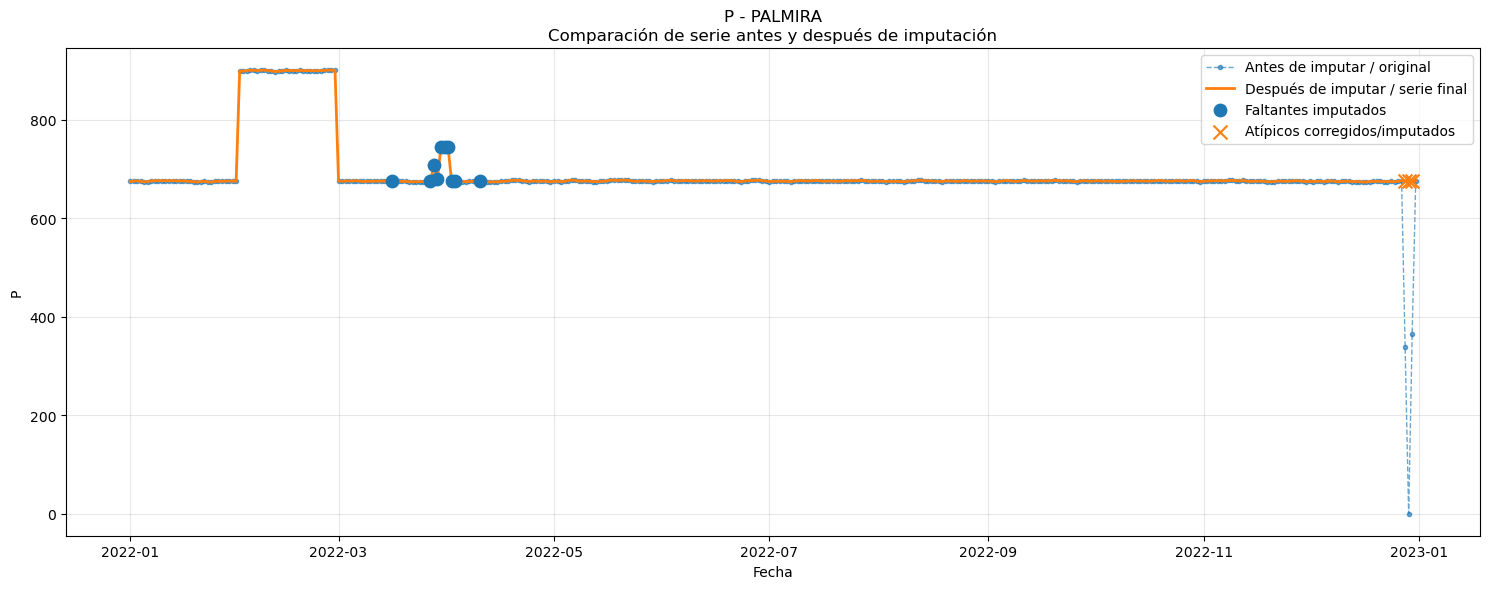

,Estacion,Variable_original_graficada,Variable_final_graficada,Registros_graficados,Valores_originales_no_nulos,Valores_finales_no_nulos,Faltantes_originales_imputados,Atipicos_corregidos
0,PALMIRA,P_original,P_final,365,355,365,10,3


## Resumen de gráficas generadas

,Estacion,Variable_original_graficada,Variable_final_graficada,Registros_graficados,Valores_originales_no_nulos,Valores_finales_no_nulos,Faltantes_originales_imputados,Atipicos_corregidos
0,PALMIRA,P_original,P_final,365,355,365,10,3


In [69]:
# ==========================================
# 8. GRÁFICA PROFESIONAL AUTOMÁTICA: ANTES VS DESPUÉS DE IMPUTAR
# ==========================================

import matplotlib.pyplot as plt
from pathlib import Path

def normalizar_estacion_txt(x):
    return str(x).strip().upper()

def diagnosticar_estaciones(resultado_final):
    estaciones_disp = sorted(
        resultado_final["Estacion"]
        .dropna()
        .astype(str)
        .str.strip()
        .str.upper()
        .unique()
    )
    print("Estaciones disponibles en resultado_final:")
    for e in estaciones_disp:
        print("-", e)
    return estaciones_disp

def preparar_carpeta_graficas():
    carpeta = Path("graficas_imputacion_antes_despues")
    carpeta.mkdir(parents=True, exist_ok=True)
    return carpeta

def graficar_imputacion_antes_despues(
    resultado_final,
    estacion=None,
    variable_original=None,
    variable_final=None,
    titulo_variable=None,
    guardar=True
):
    """
    Grafica la serie antes y después de imputar para una estación.

    Línea punteada: serie original antes de imputar.
    Línea continua: serie final después de imputar.
    Círculos: faltantes imputados.
    X: valores atípicos corregidos/imputados.
    """

    if titulo_variable is None:
        titulo_variable = VARIABLE

    if variable_original is None:
        variable_original = f"{VARIABLE}_original"

    if variable_final is None:
        variable_final = f"{VARIABLE}_final"

    df_plot = resultado_final.copy()
    df_plot["Estacion_norm"] = df_plot["Estacion"].astype(str).str.strip().str.upper()

    estaciones_disp = sorted(df_plot["Estacion_norm"].dropna().unique())

    if not estaciones_disp:
        print("No hay estaciones disponibles para graficar.")
        return None

    if estacion is None:
        estacion = estaciones_disp[0]
        print(f"No se indicó estación. Se grafica automáticamente: {estacion}")

    estacion_norm = normalizar_estacion_txt(estacion)

    if estacion_norm not in estaciones_disp:
        print(f"La estación '{estacion}' no aparece en el dataset.")
        print("Usa una de estas estaciones:")
        for e in estaciones_disp:
            print("-", e)
        return None

    if variable_original not in df_plot.columns:
        posibles_originales = [
            f"{VARIABLE}_original",
            f"{VARIABLE}_original_crudo",
            VARIABLE
        ]
        variable_original = next((c for c in posibles_originales if c in df_plot.columns), None)

    if variable_final not in df_plot.columns:
        posibles_finales = [
            f"{VARIABLE}_final",
            VARIABLE
        ]
        variable_final = next((c for c in posibles_finales if c in df_plot.columns), None)

    if variable_original is None or variable_final is None:
        print("No se encontraron columnas válidas para graficar.")
        print("Columnas disponibles:")
        print(df_plot.columns.tolist())
        return None

    df_estacion = df_plot[df_plot["Estacion_norm"] == estacion_norm].copy()
    df_estacion = df_estacion.sort_values("Fecha inicial")

    if df_estacion.empty:
        print("No hay datos para la estación seleccionada.")
        return None

    if df_estacion[variable_final].dropna().empty:
        print(f"La columna final '{variable_final}' no tiene valores para graficar.")
        display(df_estacion.head())
        return None

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        df_estacion["Fecha inicial"],
        df_estacion[variable_original],
        linestyle="--",
        marker="o",
        markersize=3,
        linewidth=1,
        alpha=0.65,
        label="Antes de imputar / original"
    )

    ax.plot(
        df_estacion["Fecha inicial"],
        df_estacion[variable_final],
        linestyle="-",
        linewidth=2,
        label="Después de imputar / serie final"
    )

    faltantes = (
        df_estacion[df_estacion["Fue_faltante_original"] == True]
        if "Fue_faltante_original" in df_estacion.columns else pd.DataFrame()
    )

    atipicos = (
        df_estacion[df_estacion["Fue_atipico"] == True]
        if "Fue_atipico" in df_estacion.columns else pd.DataFrame()
    )

    if len(faltantes) > 0:
        ax.scatter(
            faltantes["Fecha inicial"],
            faltantes[variable_final],
            s=80,
            marker="o",
            label="Faltantes imputados",
            zorder=4
        )

    if len(atipicos) > 0:
        ax.scatter(
            atipicos["Fecha inicial"],
            atipicos[variable_final],
            s=100,
            marker="x",
            label="Atípicos corregidos/imputados",
            zorder=5
        )

    ax.set_title(
        f"{titulo_variable} - {estacion_norm}\n"
        "Comparación de serie antes y después de imputación"
    )
    ax.set_xlabel("Fecha")
    ax.set_ylabel(titulo_variable)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()

    if guardar:
        carpeta = preparar_carpeta_graficas()
        nombre_seguro = "".join(ch if ch.isalnum() or ch in ["_", "-"] else "_" for ch in estacion_norm)
        ruta_grafica = carpeta / f"{VARIABLE}_antes_despues_imputacion_{nombre_seguro}.png"
        plt.savefig(ruta_grafica, dpi=150, bbox_inches="tight")
        print("Gráfica guardada en:", ruta_grafica)

    plt.show()

    resumen_grafica = pd.DataFrame([{
        "Estacion": estacion_norm,
        "Variable_original_graficada": variable_original,
        "Variable_final_graficada": variable_final,
        "Registros_graficados": len(df_estacion),
        "Valores_originales_no_nulos": int(df_estacion[variable_original].notna().sum()),
        "Valores_finales_no_nulos": int(df_estacion[variable_final].notna().sum()),
        "Faltantes_originales_imputados": int(faltantes.shape[0]) if len(faltantes) > 0 else 0,
        "Atipicos_corregidos": int(atipicos.shape[0]) if len(atipicos) > 0 else 0
    }])

    display(resumen_grafica)
    return resumen_grafica

def graficar_todas_las_estaciones_antes_despues(resultado_final):
    estaciones = diagnosticar_estaciones(resultado_final)

    resumenes = []
    for estacion in estaciones:
        print("\n" + "=" * 80)
        print(f"Generando gráfica para: {estacion}")
        print("=" * 80)
        resumen = graficar_imputacion_antes_despues(
            resultado_final=resultado_final,
            estacion=estacion,
            variable_original=f"{VARIABLE}_original",
            variable_final=f"{VARIABLE}_final",
            titulo_variable=VARIABLE,
            guardar=True
        )
        if resumen is not None:
            resumenes.append(resumen)

    if resumenes:
        resumen_total = pd.concat(resumenes, ignore_index=True)
        display(Markdown("## Resumen de gráficas generadas"))
        display(resumen_total)
        resumen_total.to_csv(f"{VARIABLE}_resumen_graficas_antes_despues.csv", index=False, encoding="utf-8-sig")

# Genera automáticamente la gráfica para todas las estaciones disponibles.
# En tu caso aparece PALMIRA, entonces la grafica sin necesidad de escribirla manualmente.
graficar_todas_las_estaciones_antes_despues(resultado_final)

## 8. Visualización de los tramos imputados

## 9. Exportar dataset completo (ambas estaciones, originales e imputados)

In [70]:
# ==========================================
# 9. EXPORTAR DATASET COMPLETO
# ==========================================

# Asegurar columna Fecha final para mantener la estructura del archivo original
if "Fecha final" not in resultado_final.columns:
    resultado_final["Fecha final"] = ""

# Dataset detallado: conserva original, imputado, final y banderas de trazabilidad
resultado_exportar_detallado = resultado_final[
    [
        "Estacion",
        "Fecha inicial",
        "Fecha final",
        f"{VARIABLE}_original",
        f"{VARIABLE}_imputado",
        f"{VARIABLE}_final",
        "Fue_faltante_original",
        "Fue_atipico",
        "Requiere_imputacion",
        "Fuente_valor",
    ]
].copy()

resultado_exportar_detallado["Fecha final"] = resultado_exportar_detallado["Fecha final"].fillna("")
resultado_exportar_detallado = (
    resultado_exportar_detallado
    .sort_values(["Estacion", "Fecha inicial"])
    .reset_index(drop=True)
)

# Dataset final: listo para análisis/modelado
resultado_exportar_final = resultado_exportar_detallado[
    [
        "Estacion",
        "Fecha inicial",
        "Fecha final",
        f"{VARIABLE}_final",
        "Fue_faltante_original",
        "Fue_atipico",
        "Requiere_imputacion",
        "Fuente_valor"
    ]
].rename(columns={f"{VARIABLE}_final": VARIABLE})

# Solo filas imputadas: faltantes y atípicos
tabla_imputados_exportar = resultado_exportar_detallado.loc[
    resultado_exportar_detallado["Requiere_imputacion"],
    [
        "Estacion",
        "Fecha inicial",
        "Fecha final",
        f"{VARIABLE}_original",
        f"{VARIABLE}_imputado",
        f"{VARIABLE}_final",
        "Fue_faltante_original",
        "Fue_atipico",
        "Fuente_valor",
    ],
].copy()

# Exportaciones
resultado_exportar_detallado.to_csv(f"{ARCHIVO_BASE}_dataset_completo_imputado_detallado_con_atipicos.csv", index=False, encoding="utf-8-sig")
resultado_exportar_final.to_csv(f"{ARCHIVO_BASE}_dataset_completo_final_con_atipicos.csv", index=False, encoding="utf-8-sig")
tabla_imputados_exportar.to_csv(f"{ARCHIVO_BASE}_valores_faltantes_y_atipicos_imputados.csv", index=False, encoding="utf-8-sig")

with pd.ExcelWriter(f"{ARCHIVO_BASE}_dataset_completo_imputado_detallado_con_atipicos.xlsx", engine="openpyxl") as writer:
    resultado_exportar_detallado.to_excel(writer, sheet_name="detalle_completo", index=False)
    resultado_exportar_final.to_excel(writer, sheet_name="dataset_final", index=False)
    tabla_imputados_exportar.to_excel(writer, sheet_name="solo_imputados", index=False)
    faltantes_resumen.to_excel(writer, sheet_name="resumen", index=False)

print("Archivos exportados correctamente:")
print(f"- {ARCHIVO_BASE}_dataset_completo_imputado_detallado_con_atipicos.csv")
print(f"- {ARCHIVO_BASE}_dataset_completo_final_con_atipicos.csv")
print(f"- {ARCHIVO_BASE}_valores_faltantes_y_atipicos_imputados.csv")
print(f"- {ARCHIVO_BASE}_dataset_completo_imputado_detallado_con_atipicos.xlsx")

display(resultado_exportar_detallado.head())
display(tabla_imputados_exportar)

Archivos exportados correctamente:
- P_dataset_completo_imputado_detallado_con_atipicos.csv
- P_dataset_completo_final_con_atipicos.csv
- P_valores_faltantes_y_atipicos_imputados.csv
- P_dataset_completo_imputado_detallado_con_atipicos.xlsx


,Estacion,Fecha inicial,Fecha final,P_original,P_imputado,P_final,Fue_faltante_original,Fue_atipico,Requiere_imputacion,Fuente_valor
0,PALMIRA,2022-01-01,,674.733333,674.733333,674.733333,False,False,False,Original
1,PALMIRA,2022-01-02,,675.304167,675.304167,675.304167,False,False,False,Original
2,PALMIRA,2022-01-03,,675.820833,675.820833,675.820833,False,False,False,Original
3,PALMIRA,2022-01-04,,674.791667,674.791667,674.791667,False,False,False,Original
4,PALMIRA,2022-01-05,,673.908333,673.908333,673.908333,False,False,False,Original


,Estacion,Fecha inicial,Fecha final,P_original,P_imputado,P_final,Fue_faltante_original,Fue_atipico,Fuente_valor
74,PALMIRA,2022-03-16,,NaN,676.044476,676.044476,True,False,Imputado_RF_faltante_original
85,PALMIRA,2022-03-27,,NaN,674.711882,674.711882,True,False,Imputado_RF_faltante_original
86,PALMIRA,2022-03-28,,NaN,707.830669,707.830669,True,False,Imputado_RF_faltante_original
87,PALMIRA,2022-03-29,,NaN,680.391794,680.391794,True,False,Imputado_RF_faltante_original
88,PALMIRA,2022-03-30,,NaN,745.152822,745.152822,True,False,Imputado_RF_faltante_original
89,PALMIRA,2022-03-31,,NaN,745.186577,745.186577,True,False,Imputado_RF_faltante_original
90,PALMIRA,2022-04-01,,NaN,745.330908,745.330908,True,False,Imputado_RF_faltante_original
91,PALMIRA,2022-04-02,,NaN,675.341142,675.341142,True,False,Imputado_RF_faltante_original
92,PALMIRA,2022-04-03,,NaN,675.023926,675.023926,True,False,Imputado_RF_faltante_original
99,PALMIRA,2022-04-10,,NaN,674.922227,674.922227,True,False,Imputado_RF_faltante_original


## 10. Lectura metodológica final

La exportación se dejó en tres niveles:

- **Dataset detallado**: conserva el valor original, el valor imputado, el valor final, la bandera de faltante original, la bandera de atípico y la fuente del dato.
- **Dataset final**: deja una sola columna `P` lista para análisis, conservando trazabilidad.
- **Archivo de solo imputados**: resume únicamente las fechas que fueron completadas por el modelo, separando faltantes originales y atípicos detectados.

Metodológicamente, los valores atípicos fueron tratados como datos no confiables: se identificaron, se marcaron, se reemplazaron temporalmente por `NaN` y luego se imputaron mediante Random Forest con variables temporales, rezagos y medias móviles.

In [71]:
# ============================================================
# TIEMPO TOTAL DE EJECUCIÓN DEL NOTEBOOK
# ============================================================

TIEMPO_FIN_NOTEBOOK = time.perf_counter()
FECHA_HORA_FIN_NOTEBOOK = datetime.now()

TIEMPO_TOTAL_SEGUNDOS = TIEMPO_FIN_NOTEBOOK - TIEMPO_INICIO_NOTEBOOK
TIEMPO_TOTAL_MINUTOS = TIEMPO_TOTAL_SEGUNDOS / 60
TIEMPO_TOTAL_HORAS = TIEMPO_TOTAL_MINUTOS / 60

nombre_notebook = globals().get("ARCHIVO_BASE", "notebook_imputacion")
nombre_notebook = str(nombre_notebook).replace(" ", "_").replace(".", "_")

tiempo_ejecucion_df = pd.DataFrame([{
    "Notebook": nombre_notebook,
    "Fecha_hora_inicio": FECHA_HORA_INICIO_NOTEBOOK,
    "Fecha_hora_fin": FECHA_HORA_FIN_NOTEBOOK,
    "Tiempo_total_segundos": round(TIEMPO_TOTAL_SEGUNDOS, 4),
    "Tiempo_total_minutos": round(TIEMPO_TOTAL_MINUTOS, 4),
    "Tiempo_total_horas": round(TIEMPO_TOTAL_HORAS, 4)
}])

display(tiempo_ejecucion_df)

archivo_tiempo_jupyter = f"{nombre_notebook}_TIEMPO_EJECUCION_NOTEBOOK.csv"
tiempo_ejecucion_df.to_csv(archivo_tiempo_jupyter, index=False, encoding="utf-8-sig")

# Guardar también en carpeta de salidas si existe.
try:
    if "TABLAS" in globals():
        tiempo_ejecucion_df.to_csv(TABLAS / f"{nombre_notebook}_TIEMPO_EJECUCION_NOTEBOOK.csv", index=False, encoding="utf-8-sig")
    elif "SALIDAS" in globals():
        tiempo_ejecucion_df.to_csv(SALIDAS / f"{nombre_notebook}_TIEMPO_EJECUCION_NOTEBOOK.csv", index=False, encoding="utf-8-sig")
except Exception as e:
    print("No fue posible guardar copia en carpeta de salidas:", e)

print("Tiempo total de ejecución del notebook:")
print(f"{TIEMPO_TOTAL_SEGUNDOS:.2f} segundos")
print(f"{TIEMPO_TOTAL_MINUTOS:.2f} minutos")
print(f"{TIEMPO_TOTAL_HORAS:.4f} horas")
print("Archivo de tiempo guardado en la carpeta principal del Jupyter:")
print(archivo_tiempo_jupyter)

,Notebook,Fecha_hora_inicio,Fecha_hora_fin,Tiempo_total_segundos,Tiempo_total_minutos,Tiempo_total_horas
0,P,2026-07-30 22:57:43.055376,2026-07-30 22:57:49.832243,6.7768,0.1129,0.0019


Tiempo total de ejecución del notebook:
6.78 segundos
0.11 minutos
0.0019 horas
Archivo de tiempo guardado en la carpeta principal del Jupyter:
P_TIEMPO_EJECUCION_NOTEBOOK.csv
